# 02 - Limpieza, transformación y preparación de los datos

**Proyecto:** Predicción de ausentismo a turnos médicos (*No-Show*)
**Fase CRISP-DM:** Preparación de los datos

**Objetivo:** resolver los problemas de calidad detectados en el EDA, construir los atributos predictivos sin fuga de información, definir la partición de los datos y el preprocesamiento adecuado para cada familia de algoritmos.

**Salidas:**
- Dataset procesado en `data/processed/turnos_procesados.csv` (con particiones y folds asignados).
- Metadatos de la preparación en `data/processed/metadatos_preparacion.json`.
- Figuras (prefijo `prep_`) y tablas en `reports/`, y resumen en `reports/tables/prep_resumen.md`.

**Momento de la predicción.** Se asume que la predicción se hace **antes del día del turno**, cuando el centro de salud todavía puede actuar (recordatorio adicional, sobreturno, reprogramación). Por lo tanto, un atributo solo es válido si su valor se conoce en ese momento. Este criterio guía todas las decisiones de este notebook.

## 0. Configuración

In [1]:
# Interruptor de datos: True = muestra de desarrollo, False = dataset completo
USAR_MUESTRA = False

In [2]:
import hashlib
import json
import sys
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.feature_selection import mutual_info_classif

ROOT = Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src import config
from src.data import RENOMBRES, cargar_datos_crudos, limpiar_datos, ruta_procesados
from src.features import (ATRIBUTOS_ARBOL, ATRIBUTOS_LINEAL, BINARIAS, CATEGORICAS, GRUPO, NUMERICAS,
                          asignar_particiones, construir_preprocesador, crear_atributos)
from src.reporting import guardar_figura, guardar_tabla, tabla_markdown, tasa_por

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

COLOR_ASISTE = "#4C72B0"
COLOR_NO_ASISTE = "#DD8452"
pct_fmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")

resumen = {"Datos utilizados": "Muestra de desarrollo" if USAR_MUESTRA else "Dataset completo"}

In [3]:
def graficar_tasa(ax, tabla, titulo, etiqueta_x="", tasa_global=None, rotar=0):
    """Barras de tasa de no-show con IC 95% y línea de la tasa global."""
    x = np.arange(len(tabla))
    err = np.vstack([tabla["tasa"] - tabla["ic_inf"], tabla["ic_sup"] - tabla["tasa"]])
    ax.bar(x, tabla["tasa"], yerr=err, color=COLOR_NO_ASISTE, alpha=0.85, capsize=3)
    if tasa_global is not None:
        ax.axhline(tasa_global, color="gray", ls="--", lw=1, label=f"Tasa global ({tasa_global:.1%})")
        ax.legend(loc="upper left", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(tabla.index.astype(str), rotation=rotar)
    ax.yaxis.set_major_formatter(pct_fmt)
    ax.set_title(titulo)
    ax.set_xlabel(etiqueta_x)
    ax.set_ylabel("Tasa de no-show")

## 1. Carga de los datos originales

In [4]:
crudo = cargar_datos_crudos(usar_muestra=USAR_MUESTRA)
n_original = len(crudo)
resumen["Instancias originales"] = f"{n_original:,}"
print(f"Instancias: {n_original:,} | Atributos: {crudo.shape[1]}")

Instancias: 110,527 | Atributos: 14


## 2. Limpieza de los datos

La función `limpiar_datos` (en `src/data.py`) aplica las acciones definidas en la síntesis del EDA:

| Acción | Detalle | Justificación |
|---|---|---|
| Renombrar columnas | Nombres en español, minúsculas, sin errores de escritura (`Hipertension`, `Handcap`, `No-show`) | Consistencia y legibilidad del código |
| Convertir tipos | Objetivo a 0/1; fechas a tipo fecha (el turno queda sin hora) | Permite calcular atributos temporales |
| Eliminar edad negativa | Valor -1 | Valor imposible |
| Eliminar edad mayor a 110 | Valor 115 (se conserva 102) | 115 años es implausible y aparece repetido; 102 es una edad posible |
| Eliminar turnos anteriores al agendamiento | Anticipación negativa | Inconsistencia temporal |
| Binarizar `discapacidad` | 0 = sin discapacidad, 1 = una o más | Los valores 2 a 4 representan el 0,18% de los turnos y el EDA no mostró asociación con el no-show |

Se eliminan filas solo cuando el valor es imposible o inconsistente, porque son muy pocas y no hay forma confiable de corregirlas. No hay valores faltantes que imputar.

In [5]:
print("Renombrado de columnas:")
pd.DataFrame(list(RENOMBRES.items()), columns=["Original", "Nuevo"]).T

Renombrado de columnas:


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
Original,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
Nuevo,paciente_id,turno_id,genero,fecha_agenda,fecha_turno,edad,barrio,beca,hipertension,diabetes,alcoholismo,discapacidad,sms_recibido,no_show


In [6]:
datos, registro_limpieza = limpiar_datos(crudo)
n_limpio = len(datos)
eliminadas = n_original - n_limpio

guardar_tabla(registro_limpieza, "prep_registro_limpieza")
resumen["Filas eliminadas en la limpieza"] = f"{eliminadas} ({eliminadas / n_original:.3%})"
print(f"Filas eliminadas: {eliminadas} ({eliminadas / n_original:.3%}) | Filas restantes: {n_limpio:,}")
registro_limpieza

Filas eliminadas: 11 (0.010%) | Filas restantes: 110,516


,Paso,Filas eliminadas,Filas restantes,Justificación
0,Edad negativa,1,110526,Valor imposible
1,Edad mayor a 110 años,5,110521,"Valor implausible (115 años, repetido en vario..."
2,Turno anterior al agendamiento,5,110516,Inconsistencia temporal: un turno no puede age...


In [7]:
# Verificaciones posteriores a la limpieza
anticipacion = (datos["fecha_turno"] - datos["fecha_agenda"].dt.normalize()).dt.days
assert datos["edad"].between(0, 110).all()
assert (anticipacion >= 0).all()
assert datos["discapacidad"].isin([0, 1]).all()
assert datos.isna().sum().sum() == 0
print("Verificaciones superadas: edades válidas, anticipación no negativa, discapacidad binaria, sin faltantes.")
print(f"Tasa de no-show tras la limpieza: {datos[config.TARGET].mean():.2%} (sin cambios relevantes)")
datos.dtypes.to_frame("tipo").T

Verificaciones superadas: edades válidas, anticipación no negativa, discapacidad binaria, sin faltantes.


Tasa de no-show tras la limpieza: 20.19% (sin cambios relevantes)


,paciente_id,turno_id,genero,fecha_agenda,fecha_turno,edad,barrio,beca,hipertension,diabetes,alcoholismo,discapacidad,sms_recibido,no_show
tipo,object,int64,object,datetime64[ns],datetime64[ns],int64,object,int64,int64,int64,int64,int32,int64,int32


## 3. Ingeniería de atributos

La función `crear_atributos` (en `src/features.py`) construye los atributos derivados. Todos se calculan fila a fila o con información del **pasado** del paciente, por lo que pueden crearse antes de la partición sin generar fuga de información.

### 3.1. Atributos temporales

| Atributo | Definición | Justificación |
|---|---|---|
| `anticipacion_dias` | Días entre el agendamiento y el turno | Atributo más asociado al no-show en el EDA (efecto 0,40) |
| `mismo_dia` | 1 si el turno se agendó para el mismo día | Captura el salto abrupto de la tasa (4,6% frente a 28,5%) |
| `dia_semana` | Día de la semana del turno (0 = lunes ... 4 = viernes) | Leve asociación en el EDA. El sábado (39 turnos) se agrupa con el viernes por ser una categoría casi vacía |
| `hora_agenda` | Hora del día en que se agendó el turno | Información disponible al agendar; no se analizó en el EDA y se explora a continuación |

La hora del turno **no** puede usarse porque `AppointmentDay` no la registra.

In [8]:
datos = crear_atributos(datos)
TASA_GLOBAL = datos[config.TARGET].mean()
print(f"Atributos tras la ingeniería: {datos.shape[1]}")
datos[["fecha_agenda", "fecha_turno", "anticipacion_dias", "mismo_dia", "dia_semana", "hora_agenda"]].head()

Atributos tras la ingeniería: 25


,fecha_agenda,fecha_turno,anticipacion_dias,mismo_dia,dia_semana,hora_agenda
0,2016-04-29 18:38:08,2016-04-29,0,1,4,18
1,2016-04-29 16:08:27,2016-04-29,0,1,4,16
2,2016-04-29 16:19:04,2016-04-29,0,1,4,16
3,2016-04-29 17:29:31,2016-04-29,0,1,4,17
4,2016-04-29 16:07:23,2016-04-29,0,1,4,16


**Exploración del nuevo atributo `hora_agenda`.** Como no se analizó en el EDA, se verifica si aporta información antes de incluirlo.

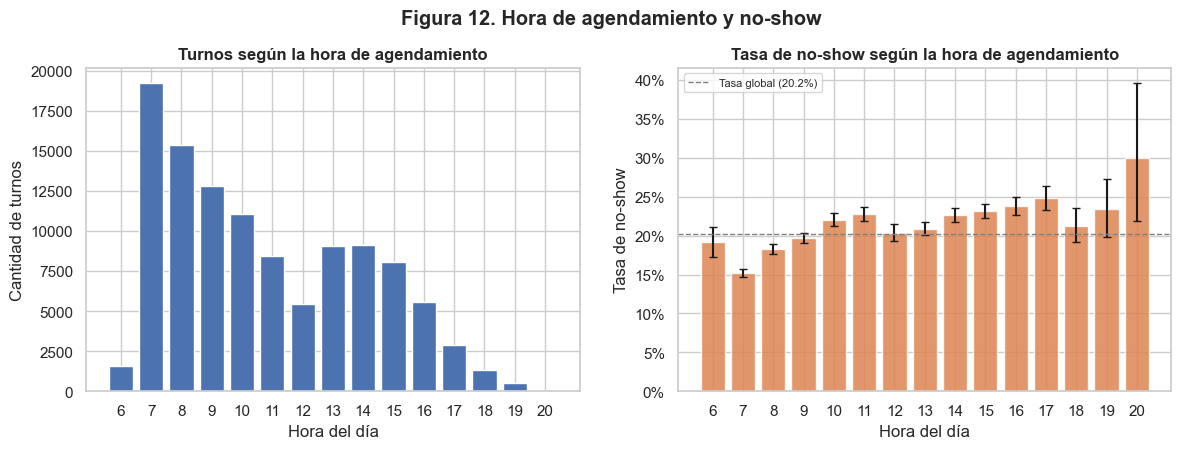

Proporción de turnos del mismo día según la hora de agendamiento (primeras horas):


hora_agenda
6    0.1934
7    0.4354
8    0.4357
9    0.3876
10   0.3258
11   0.2927
12   0.3403
13   0.3436
Name: mismo_dia, dtype: float64

In [9]:
t_hora = tasa_por(datos, "hora_agenda")
t_hora = t_hora[t_hora["n"] >= 30]  # se omiten horas con muy pocos turnos

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(t_hora.index.astype(str), t_hora["n"], color=COLOR_ASISTE)
axes[0].set_title("Turnos según la hora de agendamiento")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("Cantidad de turnos")
graficar_tasa(axes[1], t_hora, "Tasa de no-show según la hora de agendamiento", "Hora del día", TASA_GLOBAL)
fig.suptitle("Figura 12. Hora de agendamiento y no-show", fontweight="bold", y=1.02)
guardar_figura(fig, "prep_01_hora_agenda")
plt.show()

print("Proporción de turnos del mismo día según la hora de agendamiento (primeras horas):")
datos.groupby("hora_agenda")["mismo_dia"].mean().loc[t_hora.index].head(8)

**Lectura:** la tasa de no-show varía con la hora de agendamiento, pero parte de esa variación puede deberse a que los turnos del mismo día (que casi nunca terminan en ausencia) se agendan en ciertas horas. Se conserva el atributo: los modelos de árboles pueden capturar su interacción con la anticipación, y su aporte real se evaluará con la importancia por permutación.

### 3.2. Atributos demográficos y clínicos

| Atributo | Definición | Justificación |
|---|---|---|
| `mujer` | 1 si el género es femenino | Codificación binaria de `genero` |
| `grupo_edad` | Edad discretizada en 9 tramos (mismos del EDA) | La relación edad/no-show no es lineal (máximo entre 13 y 30 años). Se usa en el modelo lineal; los árboles usan la edad numérica |
| `beca`, `hipertension`, `diabetes`, `alcoholismo`, `discapacidad`, `sms_recibido` | Sin cambios (ya binarios) | — |

Los límites de los tramos de edad son fijos (definidos con criterio de dominio en el EDA), no se aprenden de los datos, por lo que la discretización no genera fuga de información.

### 3.3. Turnos del paciente en el mismo día

`turnos_mismo_dia` cuenta cuántos turnos tiene el paciente ese día. En el EDA, el 14,7% de los turnos pertenece a pacientes con más de un turno en el mismo día. Es información de la agenda, disponible antes del turno.

In [10]:
t_mismo = tasa_por(datos.assign(turnos_mismo_dia=datos["turnos_mismo_dia"].clip(upper=4)), "turnos_mismo_dia")
t_mismo.index = t_mismo.index.map(lambda v: "4+" if v == 4 else str(v))
t_mismo

,n,ausencias,tasa,ic_inf,ic_sup
turnos_mismo_dia,,,,,
1,94320,18742,0.1987,0.1962,0.2013
2,13060,2925,0.2240,0.2169,0.2312
3,2217,484,0.2183,0.2016,0.2360
4+,919,160,0.1741,0.1510,0.2000


### 3.4. Historial del paciente sin fuga de información

El EDA mostró que el resultado del turno anterior predice fuertemente el siguiente. Se construyen cuatro atributos de historial:

| Atributo | Definición |
|---|---|
| `turnos_previos` | Cantidad de turnos del paciente en días **estrictamente anteriores** |
| `ausencias_previas` | Cantidad de ausencias en esos turnos |
| `tasa_ausencias_previas` | `ausencias_previas / turnos_previos` (0 si no hay historial) |
| `tiene_historial` | 1 si el paciente tiene al menos un turno previo |

**Por qué "estrictamente anteriores":** si se usaran turnos del mismo día, un turno podría "ver" el resultado de otro turno que ocurre en paralelo, información que no existe al momento de la predicción. `tiene_historial` permite distinguir "sin historial" de "historial sin ausencias", que tienen `tasa_ausencias_previas = 0` en ambos casos.

**Atributo descartado por fuga:** la cantidad **total** de turnos del paciente en el período usaría información de turnos futuros.

**Limitación:** el historial está censurado al inicio de los datos. Los turnos de las primeras semanas tienen poco o ningún historial porque no hay registros anteriores al 29/04/2016.

In [11]:
# Verificación sobre un paciente con varios turnos, incluidos turnos múltiples en un mismo día
candidatos = datos.groupby(GRUPO).filter(lambda g: len(g) >= 4 and g["turnos_mismo_dia"].max() > 1 and g[config.TARGET].sum() > 0)
ejemplo = candidatos[GRUPO].iloc[0]
cols_hist = ["fecha_turno", config.TARGET, "turnos_mismo_dia", "turnos_previos", "ausencias_previas",
             "tasa_ausencias_previas", "tiene_historial"]
print(f"Línea de tiempo de un paciente de ejemplo ({ejemplo}):")
datos.loc[datos[GRUPO] == ejemplo, cols_hist].sort_values("fecha_turno")

Línea de tiempo de un paciente de ejemplo (12154843752835):


,fecha_turno,no_show,turnos_mismo_dia,turnos_previos,ausencias_previas,tasa_ausencias_previas,tiene_historial
21,2016-04-29,1,2,0,0,0.0000,0
27,2016-04-29,0,2,0,0,0.0000,0
51196,2016-05-05,0,2,2,1,0.5000,1
68602,2016-05-05,0,2,2,1,0.5000,1
51199,2016-05-19,1,2,4,1,0.2500,1
68604,2016-05-19,1,2,4,1,0.2500,1


In [12]:
# Control de fuga: el historial de cada turno no puede incluir turnos del mismo día ni posteriores
primer_dia = datos.groupby(GRUPO)["fecha_turno"].transform("min")
assert (datos.loc[datos["fecha_turno"] == primer_dia, "turnos_previos"] == 0).all()
assert (datos["ausencias_previas"] <= datos["turnos_previos"]).all()
print("Control superado: ningún turno del primer día del paciente tiene historial, "
      "y las ausencias previas nunca superan los turnos previos.")

Control superado: ningún turno del primer día del paciente tiene historial, y las ausencias previas nunca superan los turnos previos.


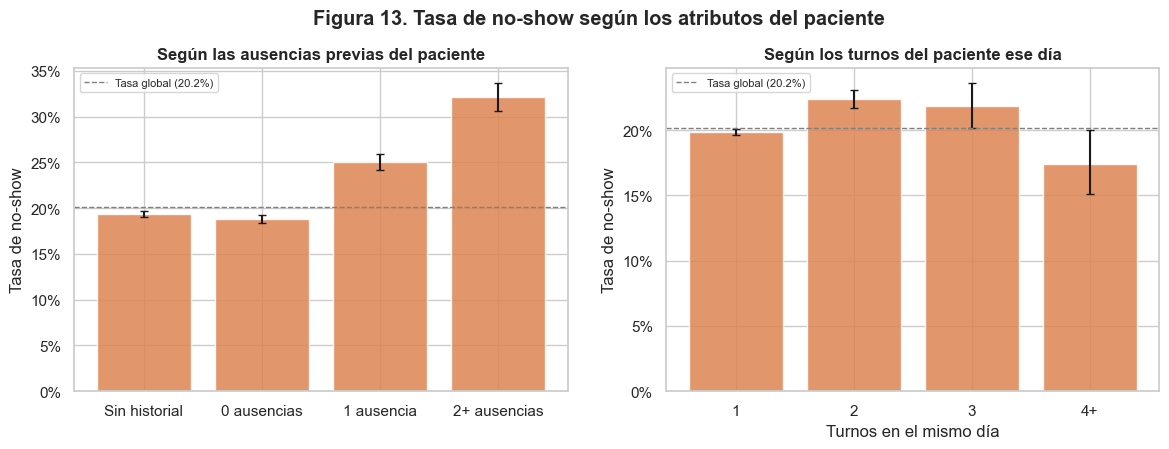

,n,ausencias,tasa,ic_inf,ic_sup
historial,,,,,
Sin historial,66286,12843,0.1938,0.1908,0.1968
0 ausencias,30119,5677,0.1885,0.1841,0.1929
1 ausencia,10472,2622,0.2504,0.2422,0.2588
2+ ausencias,3639,1169,0.3212,0.3063,0.3366


In [13]:
etiqueta_hist = np.select(
    [datos["tiene_historial"] == 0, datos["ausencias_previas"] == 0, datos["ausencias_previas"] == 1],
    ["Sin historial", "0 ausencias", "1 ausencia"], default="2+ ausencias",
)
orden_hist = ["Sin historial", "0 ausencias", "1 ausencia", "2+ ausencias"]
t_hist = tasa_por(datos.assign(historial=etiqueta_hist), "historial", orden=orden_hist)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
graficar_tasa(axes[0], t_hist, "Según las ausencias previas del paciente", "", TASA_GLOBAL)
graficar_tasa(axes[1], t_mismo, "Según los turnos del paciente ese día", "Turnos en el mismo día", TASA_GLOBAL)
fig.suptitle("Figura 13. Tasa de no-show según los atributos del paciente", fontweight="bold", y=1.02)
guardar_figura(fig, "prep_02_historial")
plt.show()

guardar_tabla(t_hist, "prep_tasa_historial", index=True)
resumen["No-show sin historial"] = f"{t_hist.loc['Sin historial', 'tasa']:.1%}"
resumen["Turnos con historial previo"] = f"{datos['tiene_historial'].mean():.1%}"
resumen["No-show con 2 o más ausencias previas"] = f"{t_hist.loc['2+ ausencias', 'tasa']:.1%}"
resumen["No-show con historial sin ausencias"] = f"{t_hist.loc['0 ausencias', 'tasa']:.1%}"
t_hist

**Lectura:** con la definición estricta (solo días anteriores), los pacientes sin historial y los que asistieron a todos sus turnos previos tienen una tasa similar a la global. El efecto aparece con las ausencias previas: la tasa crece con cada ausencia acumulada. Por eso el atributo informativo es `ausencias_previas` (y su tasa), más que el simple hecho de tener historial. El efecto es algo menor que el observado en el EDA porque allí el "turno anterior" podía ser otro turno del mismo día, cuyo resultado está muy correlacionado con el actual.

### 3.5. Atributos excluidos del modelado

| Atributo | Motivo |
|---|---|
| `paciente_id`, `turno_id` | Identificadores sin valor predictivo. `paciente_id` se conserva solo para agrupar la partición |
| `fecha_agenda`, `fecha_turno` | Su información ya está en los atributos derivados. Usar la fecha absoluta no generaliza a períodos futuros |
| `genero` | Reemplazado por `mujer` |
| Total de turnos del paciente en el período | Fuga de información (usa turnos futuros) |
| Hora del turno | No disponible en los datos |

## 4. Dataset final

### 4.1. Diccionario de atributos para el modelado

In [14]:
origen = {
    "edad": "Original", "beca": "Original", "hipertension": "Original", "diabetes": "Original",
    "alcoholismo": "Original", "sms_recibido": "Original", "barrio": "Original",
    "discapacidad": "Transformado (binarizado)", "mujer": "Transformado (de genero)",
    "grupo_edad": "Derivado (discretización de edad)",
}
descripcion = {
    "edad": "Edad en años", "anticipacion_dias": "Días entre agendamiento y turno",
    "hora_agenda": "Hora en que se agendó el turno", "turnos_mismo_dia": "Turnos del paciente ese día",
    "turnos_previos": "Turnos del paciente en días anteriores", "ausencias_previas": "Ausencias en días anteriores",
    "tasa_ausencias_previas": "Proporción de ausencias previas", "mujer": "Género femenino",
    "beca": "Inscripto en Bolsa Família", "hipertension": "Tiene hipertensión", "diabetes": "Tiene diabetes",
    "alcoholismo": "Tiene alcoholismo", "discapacidad": "Tiene al menos una discapacidad",
    "sms_recibido": "Recibió SMS recordatorio", "mismo_dia": "Turno agendado para el mismo día",
    "tiene_historial": "Tiene turnos previos", "dia_semana": "Día de la semana del turno (0 = lunes)",
    "grupo_edad": "Tramo de edad", "barrio": "Barrio de atención",
}
atributos = NUMERICAS + BINARIAS + CATEGORICAS
diccionario = pd.DataFrame([
    {"Atributo": a,
     "Tipo": "Numérico" if a in NUMERICAS else ("Binario" if a in BINARIAS else "Categórico"),
     "Origen": origen.get(a, "Derivado"),
     "Descripción": descripcion[a],
     "Árboles": "Sí" if a in ATRIBUTOS_ARBOL else "No",
     "Lineal": "Sí" if a in ATRIBUTOS_LINEAL else "No"}
    for a in atributos
])
guardar_tabla(diccionario, "prep_diccionario_atributos")
resumen["Atributos para modelos de árboles"] = len(ATRIBUTOS_ARBOL)
resumen["Atributos para el modelo lineal (antes de codificar)"] = len(ATRIBUTOS_LINEAL)
diccionario

,Atributo,Tipo,Origen,Descripción,Árboles,Lineal
0,edad,Numérico,Original,Edad en años,Sí,No
1,anticipacion_dias,Numérico,Derivado,Días entre agendamiento y turno,Sí,Sí
2,hora_agenda,Numérico,Derivado,Hora en que se agendó el turno,Sí,Sí
3,turnos_mismo_dia,Numérico,Derivado,Turnos del paciente ese día,Sí,Sí
4,turnos_previos,Numérico,Derivado,Turnos del paciente en días anteriores,Sí,Sí
5,ausencias_previas,Numérico,Derivado,Ausencias en días anteriores,Sí,Sí
6,tasa_ausencias_previas,Numérico,Derivado,Proporción de ausencias previas,Sí,Sí
7,mujer,Binario,Transformado (de genero),Género femenino,Sí,Sí
8,beca,Binario,Original,Inscripto en Bolsa Família,Sí,Sí
9,hipertension,Binario,Original,Tiene hipertensión,Sí,Sí


In [15]:
datos[NUMERICAS].describe().T

,count,mean,std,min,25%,50%,75%,max
edad,"110,516.0000",37.0859,23.1045,0.0000,18.0000,37.0000,55.0000,102.0000
anticipacion_dias,"110,516.0000",10.1843,15.2552,0.0000,0.0000,4.0000,15.0000,179.0000
hora_agenda,"110,516.0000",10.7746,3.2162,6.0000,8.0000,10.0000,13.0000,21.0000
turnos_mismo_dia,"110,516.0000",1.1875,0.5231,1.0000,1.0000,1.0000,1.0000,10.0000
turnos_previos,"110,516.0000",1.1765,3.7974,0.0000,0.0000,0.0000,1.0000,83.0000
ausencias_previas,"110,516.0000",0.1844,0.6122,0.0000,0.0000,0.0000,0.0000,15.0000
tasa_ausencias_previas,"110,516.0000",0.0781,0.2361,0.0000,0.0000,0.0000,0.0000,1.0000


## 5. Partición de los datos

### 5.1. Estrategia

Se usa una partición **80% entrenamiento / 20% prueba**, con dos condiciones simultáneas (`StratifiedGroupKFold`):

- **Estratificada por la variable objetivo**, para que ambos conjuntos conserven la proporción de no-show (recomendación de la docente sobre el desbalance).
- **Agrupada por paciente**: todos los turnos de un paciente quedan del mismo lado. El 82% de los grupos de turnos de un mismo paciente en un mismo día tienen el mismo resultado; si se repartieran entre entrenamiento y prueba, el modelo podría "reconocer" al paciente y la evaluación sería optimista.

Dentro del entrenamiento se asignan además **5 folds de validación cruzada**, con el mismo criterio. Quedan guardados en la columna `fold` para que **todos los modelos se comparen con exactamente las mismas particiones**.

**Alternativa descartada:** una partición temporal reflejaría mejor el uso real, pero el período abarca solo 27 días con turnos: el conjunto de prueba quedaría reducido a una semana y a días con posible comportamiento atípico.

**Uso del conjunto de prueba:** no se usa para explorar, ajustar ni seleccionar. Se evalúa **una única vez** en el notebook 05.

In [16]:
datos = asignar_particiones(datos, n_folds=5, seed=config.SEED)

tabla_part = datos.groupby("particion").agg(
    turnos=(config.TARGET, "size"), pacientes=(GRUPO, "nunique"), tasa_no_show=(config.TARGET, "mean")
).reindex(["train", "test"])
tabla_part["% turnos"] = tabla_part["turnos"] / len(datos) * 100
pac_train = set(datos.loc[datos["particion"] == "train", GRUPO])
pac_test = set(datos.loc[datos["particion"] == "test", GRUPO])
solapados = len(pac_train & pac_test)
assert solapados == 0, "Hay pacientes en ambos conjuntos"

guardar_tabla(tabla_part, "prep_particion", index=True)
resumen["Entrenamiento"] = f"{tabla_part.loc['train', 'turnos']:,} turnos ({tabla_part.loc['train', 'tasa_no_show']:.2%} no-show)"
resumen["Prueba"] = f"{tabla_part.loc['test', 'turnos']:,} turnos ({tabla_part.loc['test', 'tasa_no_show']:.2%} no-show)"
print(f"Pacientes presentes en ambos conjuntos: {solapados}")
tabla_part

Pacientes presentes en ambos conjuntos: 0


,turnos,pacientes,tasa_no_show,% turnos
particion,,,,
train,88301,49737,0.2010,79.8988
test,22215,12559,0.2055,20.1012


In [17]:
tabla_folds = datos[datos["particion"] == "train"].groupby("fold").agg(
    turnos=(config.TARGET, "size"), pacientes=(GRUPO, "nunique"), tasa_no_show=(config.TARGET, "mean")
)
guardar_tabla(tabla_folds, "prep_folds", index=True)
print(f"Rango de la tasa de no-show entre folds: {tabla_folds['tasa_no_show'].min():.2%} a {tabla_folds['tasa_no_show'].max():.2%}")
tabla_folds

Rango de la tasa de no-show entre folds: 19.55% a 20.32%


,turnos,pacientes,tasa_no_show
fold,,,
0,18010,10015,0.2022
1,17760,10014,0.2010
2,17521,9877,0.1955
3,17482,9916,0.2029
4,17528,9915,0.2032


## 6. Relevancia de los atributos (solo entrenamiento)

Como verificación de los atributos construidos, se calcula la **información mutua** entre cada atributo y la variable objetivo. Mide cuánto se reduce la incertidumbre sobre el no-show al conocer el atributo, y capta relaciones no lineales. Se calcula **solo sobre el conjunto de entrenamiento**, para que la prueba no influya en ninguna decisión.

**Corrección por cardinalidad.** El estimador de información mutua sobrestima la relevancia de los atributos con muchos valores distintos (edad, barrio, anticipación). Para comparar atributos de forma justa se aplica la corrección de Miller-Madow, que resta el sesgo esperado $(k-1)/(2N)$, donde $k$ es la cantidad de valores distintos del atributo y $N$ la cantidad de turnos.

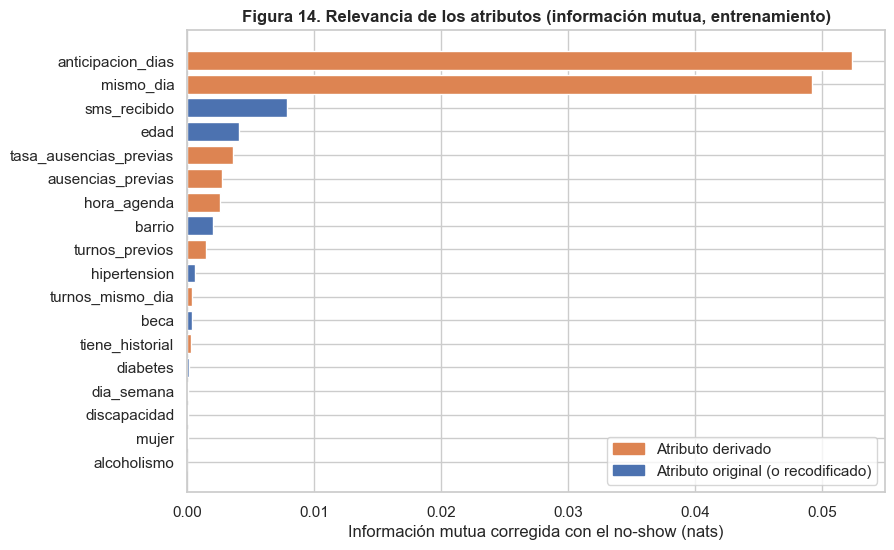

,valores_distintos,im_bruta,im_corregida
atributo,,,
anticipacion_dias,126,0.0530,0.0523
mismo_dia,2,0.0492,0.0492
sms_recibido,2,0.0079,0.0079
edad,102,0.0046,0.0040
tasa_ausencias_previas,63,0.0039,0.0036
ausencias_previas,15,0.0028,0.0027
hora_agenda,16,0.0027,0.0026
barrio,81,0.0025,0.0020
turnos_previos,75,0.0019,0.0015


In [18]:
train = datos[datos["particion"] == "train"]
X_mi = train[NUMERICAS + BINARIAS + ["dia_semana", "barrio"]].copy()
X_mi["barrio"] = X_mi["barrio"].astype("category").cat.codes
X_mi["tasa_ausencias_previas"] = (X_mi["tasa_ausencias_previas"] * 100).round().astype(int)
mi_bruta = pd.Series(
    mutual_info_classif(X_mi, train[config.TARGET], discrete_features=True, random_state=config.SEED),
    index=X_mi.columns,
)
valores_distintos = X_mi.nunique()
sesgo = (valores_distintos - 1) / (2 * len(X_mi))
tabla_mi = pd.DataFrame({"valores_distintos": valores_distintos, "im_bruta": mi_bruta,
                         "im_corregida": (mi_bruta - sesgo).clip(lower=0)}).sort_values("im_corregida", ascending=False)
tabla_mi.index.name = "atributo"
mi = tabla_mi["im_corregida"]

fig, ax = plt.subplots(figsize=(9, 6))
ORIGINALES = {"edad", "beca", "hipertension", "diabetes", "alcoholismo", "discapacidad", "sms_recibido", "barrio", "mujer"}
colores = [COLOR_ASISTE if c in ORIGINALES else COLOR_NO_ASISTE for c in mi.index]
ax.barh(mi.index[::-1], mi.values[::-1], color=colores[::-1])
ax.set_xlabel("Información mutua corregida con el no-show (nats)")
ax.set_title("Figura 14. Relevancia de los atributos (información mutua, entrenamiento)")
ax.legend(handles=[Patch(color=COLOR_NO_ASISTE, label="Atributo derivado"),
                   Patch(color=COLOR_ASISTE, label="Atributo original (o recodificado)")], loc="lower right")
guardar_figura(fig, "prep_03_informacion_mutua")
plt.show()

guardar_tabla(tabla_mi, "prep_informacion_mutua", index=True)
tabla_mi

**Decisión sobre la selección de atributos:** se conservan todos los atributos, incluidos los de relevancia muy baja (como `alcoholismo` o `mujer`), por tres razones:

1. La dimensionalidad ya es baja (18 atributos para los árboles), por lo que no hay un problema de costo computacional.
2. Una relevancia individual baja no descarta que el atributo aporte en interacción con otros, algo que los ensambles de árboles pueden capturar.
3. La contribución real de cada atributo se evaluará después del modelado con **importancia por permutación**, que mide su efecto sobre el rendimiento del modelo.

La información mutua permite además verificar el aporte de la ingeniería de atributos: los atributos derivados (en naranja en la Figura 14) pueden compararse directamente con los originales. La interpretación de este ranking se incluye en el informe a partir de la ejecución sobre el dataset completo.

## 7. Preprocesamiento por familia de algoritmos

Los algoritmos tienen requisitos distintos, por lo que se definen dos preprocesadores (función `construir_preprocesador` en `src/features.py`):

| Transformación | Árboles (Árbol, RF, LightGBM, XGBoost) | Lineal (Regresión Logística) |
|---|---|---|
| Atributos numéricos | Sin cambios (los árboles no dependen de la escala) | Logaritmo (`log1p`) en atributos muy asimétricos y estandarización |
| Edad | Numérica | Discretizada en tramos con *one-hot* (relación no lineal) |
| Día de la semana | Ordinal (0 a 4) | *One-hot* |
| Barrio (81 categorías) | Codificación por objetivo | Codificación por objetivo y estandarización |
| Binarias | Sin cambios | Sin cambios |

**Codificación por objetivo del barrio.** Reemplaza cada barrio por su tasa de no-show, suavizada hacia la tasa global cuando el barrio tiene pocos turnos. Se eligió frente a *one-hot* (81 columnas dispersas) y frente a agrupar barrios chicos (perdería la señal: 31 de 81 barrios difieren de la tasa global). Como usa la variable objetivo, se ajusta **dentro** de cada fold de entrenamiento, y además `TargetEncoder` aplica validación cruzada interna para que un turno no se codifique con su propio resultado.

**Regla contra la fuga de información:** ningún preprocesador se ajusta en este notebook sobre todos los datos. Se incluyen como primer paso de los pipelines de modelado, de modo que en cada fold se ajustan solo con los datos de entrenamiento de ese fold. A continuación se muestra una demostración ajustando sobre entrenamiento y aplicando sobre prueba.

In [19]:
train = datos[datos["particion"] == "train"]
test = datos[datos["particion"] == "test"]

demostracion = []
for familia, cols in [("arbol", ATRIBUTOS_ARBOL), ("lineal", ATRIBUTOS_LINEAL)]:
    pre = construir_preprocesador(familia).set_output(transform="pandas")
    X_tr = pre.fit_transform(train[cols], train[config.TARGET])
    X_te = pre.transform(test[cols])
    demostracion.append({
        "Familia": familia, "Atributos de entrada": len(cols), "Columnas tras preprocesar": X_tr.shape[1],
        "Faltantes (train + test)": int(X_tr.isna().sum().sum() + X_te.isna().sum().sum()),
    })
    if familia == "lineal":
        X_lineal_demo = X_tr

demostracion = pd.DataFrame(demostracion)
assert demostracion["Faltantes (train + test)"].eq(0).all()
guardar_tabla(demostracion, "prep_preprocesadores")
demostracion

,Familia,Atributos de entrada,Columnas tras preprocesar,Faltantes (train + test)
0,arbol,18,18,0
1,lineal,18,28,0


In [20]:
print("Columnas del preprocesador lineal:")
print(list(X_lineal_demo.columns))
X_lineal_demo.describe().T[["mean", "std", "min", "max"]].head(8)

Columnas del preprocesador lineal:
['anticipacion_dias', 'turnos_mismo_dia', 'turnos_previos', 'ausencias_previas', 'hora_agenda', 'tasa_ausencias_previas', 'grupo_edad_1-5', 'grupo_edad_6-12', 'grupo_edad_13-18', 'grupo_edad_19-30', 'grupo_edad_31-45', 'grupo_edad_46-60', 'grupo_edad_61-75', 'grupo_edad_76+', 'dia_semana_1', 'dia_semana_2', 'dia_semana_3', 'dia_semana_4', 'mujer', 'beca', 'hipertension', 'diabetes', 'alcoholismo', 'discapacidad', 'sms_recibido', 'mismo_dia', 'tiene_historial', 'barrio']


,mean,std,min,max
anticipacion_dias,-0.0000,1.0000,-1.1196,2.6647
turnos_mismo_dia,0.0000,1.0000,-0.3908,8.8774
turnos_previos,-0.0000,1.0000,-0.6701,6.0039
ausencias_previas,-0.0000,1.0000,-0.3576,8.9138
hora_agenda,-0.0000,1.0000,-1.4850,3.1758
tasa_ausencias_previas,-0.0000,1.0000,-0.3291,3.9200
grupo_edad_1-5,0.0739,0.2616,0.0000,1.0000
grupo_edad_6-12,0.0828,0.2756,0.0000,1.0000


## 8. Guardado del dataset procesado

Se guarda el dataset limpio con todos los atributos, la partición y los folds. También se guardan los metadatos de la preparación, incluido un *hash* SHA-256 del archivo: se registrará en MLflow para garantizar que todos los modelos se entrenaron con exactamente los mismos datos.

In [21]:
columnas_finales = ([GRUPO, "turno_id", "fecha_agenda", "fecha_turno"] + NUMERICAS + BINARIAS + CATEGORICAS
                    + [config.TARGET, "particion", "fold"])
procesado = datos[columnas_finales].sort_values(["fecha_turno", GRUPO, "turno_id"]).reset_index(drop=True)

ruta = ruta_procesados(USAR_MUESTRA)
ruta.parent.mkdir(parents=True, exist_ok=True)
procesado.to_csv(ruta, index=False)
hash_datos = hashlib.sha256(ruta.read_bytes()).hexdigest()

metadatos = {
    "fecha_generacion": datetime.now().isoformat(timespec="seconds"),
    "datos": resumen["Datos utilizados"],
    "archivo": ruta.name,
    "sha256": hash_datos,
    "semilla": config.SEED,
    "filas_originales": n_original,
    "filas_eliminadas": eliminadas,
    "filas_finales": len(procesado),
    "objetivo": config.TARGET,
    "grupo": GRUPO,
    "atributos": {"numericas": NUMERICAS, "binarias": BINARIAS, "categoricas": CATEGORICAS,
                  "arbol": ATRIBUTOS_ARBOL, "lineal": ATRIBUTOS_LINEAL},
    "particion": {k: int(v) for k, v in procesado["particion"].value_counts().items()},
    "folds": int(procesado.loc[procesado["particion"] == "train", "fold"].nunique()),
}
ruta_meta = ruta.with_name(ruta.stem.replace("turnos_procesados", "metadatos_preparacion") + ".json")
ruta_meta.write_text(json.dumps(metadatos, indent=2, ensure_ascii=False), encoding="utf-8")

resumen["Instancias finales"] = f"{len(procesado):,}"
resumen["Hash SHA-256 del dataset procesado"] = f"`{hash_datos[:16]}...`"
print(f"Dataset procesado: {ruta} ({len(procesado):,} filas, {procesado.shape[1]} columnas)")
print(f"Metadatos: {ruta_meta}")
print(f"SHA-256: {hash_datos}")

Dataset procesado: C:\Users\poriglia\tfi-mineria-datos-noshow\data\processed\turnos_procesados.csv (110,516 filas, 26 columnas)
Metadatos: C:\Users\poriglia\tfi-mineria-datos-noshow\data\processed\metadatos_preparacion.json
SHA-256: 40d361e54c4cd001e1c062e326c199206e44089db0d0ceb24d7879bd8a0413e6


### 8.1. Resumen de la preparación

In [22]:
cifras = pd.DataFrame(list(resumen.items()), columns=["Indicador", "Valor"])

lineas = [
    "# Resumen de la preparación de los datos",
    "",
    f"**Datos utilizados:** {resumen['Datos utilizados']}",
    "",
    "## Cifras clave",
    "",
    tabla_markdown(cifras),
    "",
    "## Registro de limpieza",
    "",
    tabla_markdown(registro_limpieza),
    "",
    "## Partición entrenamiento / prueba",
    "",
    tabla_markdown(tabla_part.round(4), index=True),
    "",
    "## Folds de validación cruzada (entrenamiento)",
    "",
    tabla_markdown(tabla_folds.round(4), index=True),
    "",
    "## Tasa de no-show según el historial del paciente",
    "",
    tabla_markdown(t_hist[["n", "tasa", "ic_inf", "ic_sup"]].round(4), index=True),
    "",
    "## Tasa de no-show según los turnos del paciente ese día",
    "",
    tabla_markdown(t_mismo[["n", "tasa", "ic_inf", "ic_sup"]].round(4), index=True),
    "",
    "## Información mutua con el objetivo (entrenamiento)",
    "",
    tabla_markdown(tabla_mi.round(5), index=True),
    "",
    "## Preprocesadores",
    "",
    tabla_markdown(demostracion),
    "",
]
ruta_resumen = config.TABLES_DIR / "prep_resumen.md"
ruta_resumen.write_text("\n".join(lineas), encoding="utf-8")
print(f"Resumen guardado en: {ruta_resumen}")
cifras

Resumen guardado en: C:\Users\poriglia\tfi-mineria-datos-noshow\reports\tables\prep_resumen.md


,Indicador,Valor
0,Datos utilizados,Dataset completo
1,Instancias originales,"110,527"
2,Filas eliminadas en la limpieza,11 (0.010%)
3,No-show sin historial,19.4%
4,Turnos con historial previo,40.0%
5,No-show con 2 o más ausencias previas,32.1%
6,No-show con historial sin ausencias,18.8%
7,Atributos para modelos de árboles,18
8,Atributos para el modelo lineal (antes de codi...,18
9,Entrenamiento,"88,301 turnos (20.10% no-show)"
